# 31 — Resultados finales: objetivos, hipótesis, costo y límites

**Autor:** Jason Sepúlveda S.
**Proyecto:** Evaluación experimental de la extracción automática y la representación
persistente de decisiones organizacionales frente a Recuperación Aumentada (RAG)
**Depende de:** [notebook 28](28-jss-experimento-a.ipynb) ·
[notebook 29](29-jss-anotacion-f3-referencia.ipynb) ·
[notebook 30](30-jss-experimento-b.ipynb) ·
[ADR 0010](../docs/decisions/0010-adr-decisiones-del-analisis-del-experimento-b.md) ·
[ADR 0017](../docs/decisions/0017-adr-medicion-de-h4.md) ·
[ADR 0018](../docs/decisions/0018-adr-medicion-de-h2-y-h3.md) · issue #294 (épica #288)

**Alcance.** Reúne en un solo lugar la respuesta a cada objetivo específico (OE1 a OE4) y a cada
hipótesis (D16 y H1 a H4), el costo y la latencia, la lectura del punto de equilibrio, las
salvedades sobre la validez del juez automático y las limitaciones. **No calcula ninguna cifra
nueva** ni dibuja figuras propias: lee las salidas guardadas (`informe.json`, `analisis.json`,
`juez-humano.json`, `oe4-resumen.json`, `validacion-manual.json`) y las tablas `reports/tables/final-*`,
y comprueba que coinciden entre sí. No llama a ningún modelo. **Requisito:** ninguna sección necesita
Ollama ni el corpus; las figuras se leen de `reports/figures/` si existen y, si no, se vuelven a
dibujar desde las tablas.

> **Aviso de alcance (ADR 0005).** Las series son series de **evaluación**. El notebook muestra solo
> **identificadores de pregunta y de serie, etiquetas y cifras agregadas**. No muestra ni cita texto de
> respuestas, de transcripciones ni de decisiones.

## Los términos, en simple

| Término | Qué significa |
|---|---|
| Condición | Qué contexto recibe el mismo generador para responder: C0 ninguno, C1 fragmentos del texto (RAG convencional), C2 la base compilada automáticamente, C3 la base con las decisiones de la referencia humana. |
| Estrato | Tipo de pregunta: E1 hecho puntual de una decisión, E2 estado vigente, E3 evolución (relaciones entre decisiones), E4 sin respuesta en el corpus. |
| D16 | Criterio principal preregistrado: el intervalo de 95 % de la diferencia pareada C2 − C1 en E3 debe quedar por encima de 0. |
| H1 a H4 | Hipótesis preregistradas ([documento 03](../docs/avances/03-jss-objetivos.md)). |
| Punto de equilibrio | Número de consultas a partir del cual compilar la base y consultarla resulta más barato que consultar siempre por RAG. |
| Kappa | Acuerdo entre dos evaluadores descontando el azar; el umbral del juez es 0,70. |

---

# 1. Fuentes

**Qué se hace.** Se leen las salidas guardadas de las dos corridas formales y las tablas finales. Si
falta alguna, el notebook lo dice y se detiene en esa sección en vez de inventar la cifra.

In [1]:
import json
import tempfile
import warnings
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

from afg.evaluation.judge_human_check import check_judge_by_condition, read_csv_rows
from afg.experiments.final_figures import draw_all
from afg.experiments.final_tables import FinalTables
from afg.shared.paths import EXPERIMENT_A_DIR, EXPERIMENT_B_DIR, PROJECT_ROOT

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)

A_RUN, B_RUN = "experimento-a-formal", "experimento-b-formal"
A_DIR, B_DIR = EXPERIMENT_A_DIR / A_RUN, EXPERIMENT_B_DIR / B_RUN
TABLES_DIR = PROJECT_ROOT / "reports" / "tables"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
SET = "final"


def read(path):
    return json.loads(path.read_text(encoding="utf-8"))


def es(value, digits=2):
    return f"{value:.{digits}f}".replace(".", ",")


def pct(value, digits=1):
    return es(100 * value, digits) + " %"


def ci(low, high, digits=2):
    return f"[{es(low, digits)}; {es(high, digits)}]"


def hms(seconds):
    seconds = round(seconds)
    h, rest = divmod(seconds, 3600)
    m, s = divmod(rest, 60)
    return f"{h} h {m} min {s} s" if h else f"{m} min {s} s"


informe = read(A_DIR / "informe.json")
validation = read(A_DIR / "validacion-manual.json")
relations_a = informe["relations"]["pooled"]
hyp_a = informe["hypotheses"]
manifest_b = read(B_DIR / "manifest.json")
analysis = read(B_DIR / "analisis.json")
juez = read(B_DIR / "juez-humano.json")
oe4 = read(B_DIR / "oe4-resumen.json")
agreement = pd.read_csv(TABLES_DIR / "agreement-pooled.csv")

TABLES = {
    path.stem.removeprefix(f"{SET}-"): pd.read_csv(path)
    for path in sorted(TABLES_DIR.glob(f"{SET}-*.csv"))
}
assert set(TABLES) == {
    "a-headline",
    "a-relations",
    "b-cells",
    "b-paired",
    "break-even",
    "cost-latency",
    "oe4-stages",
}, sorted(TABLES)

pd.DataFrame(
    [
        {"fuente": "Experimento A", "corrida": A_RUN, "reportable": informe["reportable"]},
        {"fuente": "Experimento B", "corrida": B_RUN, "reportable": analysis["reportable"]},
    ]
).set_index("fuente")

,corrida,reportable
fuente,,
Experimento A,experimento-a-formal,True
Experimento B,experimento-b-formal,True


In [2]:
counts = manifest_b["counts"]
display(
    Markdown(
        f"**Lectura.** Ambas corridas son de la partición de evaluación y reportables. A: "
        f"{len(informe['series'])} series, {len(informe['runs'])} repeticiones. B: "
        f"{counts['questions']} preguntas, {len(manifest_b['conditions'])} condiciones, "
        f"{manifest_b['settings']['runs']} repeticiones, {counts['complete']} "
        f"de {counts['expected']} "
        f"registros completos y {counts['errors']} con error. Generador "
        f"`{manifest_b['settings']['generative_model']}`, juez "
        f"`{manifest_b['settings']['judge_model']}`. "
        f"Las {len(TABLES)} tablas `final-*` están presentes."
    )
)

**Lectura.** Ambas corridas son de la partición de evaluación y reportables. A: 11 series, 3 repeticiones. B: 99 preguntas, 4 condiciones, 3 repeticiones, 1188 de 1188 registros completos y 0 con error. Generador `qwen3:8b`, juez `gpt-oss:20b`. Las 7 tablas `final-*` están presentes.

---

# 2. Respuesta a cada objetivo específico

**Pregunta.** ¿Qué se encontró en OE1, OE2, OE3 y OE4?

**Qué se muestra.** Una fila por objetivo, con la cifra principal y el notebook o archivo del que sale.
Las cifras de OE1 salen del notebook 29 (la referencia final) y de `agreement-pooled.csv`; las de OE2, de
`informe.json` y `validacion-manual.json`; las de OE3, de `analisis.json` y `juez-humano.json`; las de
OE4, de `oe4-resumen.json` y de los registros (notebook 30, sección 4).

## 2.1 OE1: la referencia humana

La referencia final tiene 14 series, 358 decisiones y 46 relaciones (notebook 29); 278 decisiones y
37 relaciones (24 de evolución) corresponden a las once series de evaluación. La confiabilidad se
midió en las cuatro series de control de la Fase 2 (`agreement-pooled.csv`).

In [3]:
REFERENCE = {  # notebook 29, "La referencia final"
    "series": 14,
    "decisiones": 358,
    "relaciones": 46,
    "decisiones de evaluación": 278,
    "relaciones de evaluación": 37,
    "relaciones de evolución en evaluación": 24,
}
# La referencia de evaluación que usa el Experimento A: 834 = 3 repeticiones x 278 decisiones.
pooled_reference = informe["curve"][0]["origin_meetings"]["pooled"]
n_reference = pooled_reference["tp"] + pooled_reference["fn"]
assert n_reference == 3 * REFERENCE["decisiones de evaluación"]
kinds = pd.Series(informe["reference_kinds"])
adjudicated = int((kinds == "adjudicated").sum())
phase2 = agreement[agreement["scope"] == "phase 2"].set_index("axis")
rows = []
for axis, label in (("existence", "existencia"), ("type", "tipo"), ("direction", "dirección")):
    row = phase2.loc[axis]
    rows.append(
        {
            "pregunta": label,
            "pares": int(row["n_items"]),
            "desacuerdos": int(row["n_disagreements"]),
            "acuerdo simple": pct(row["percent_agreement"]),
            "kappa": "indefinido" if pd.isna(row["kappa"]) else es(row["kappa"], 3),
        }
    )
display(pd.Series(REFERENCE, name="referencia final (notebook 29)").to_frame())
display(pd.DataFrame(rows).set_index("pregunta").rename_axis("Fase 2 (cuatro series de control)"))
print(
    f"Series de evaluación con referencia adjudicada: {adjudicated} de {len(kinds)}; "
    f"con un solo anotador: {len(kinds) - adjudicated}."
)
try:  # comprobación opcional con los archivos de la referencia, si están en el equipo
    from afg.experiments.question_bank import evaluation_series
    from afg.extraction.openkos.gold_bundle import load_gold_relations
    from afg.shared.config import load_corpus_config

    all_series = tuple(load_corpus_config()["oe1"]["series"])
    total = sum(len(load_gold_relations(s)) for s in all_series)
    evaluation = sum(len(load_gold_relations(s)) for s in evaluation_series())
    assert (total, evaluation) == (46, 37)
    print("Comprobación: 46 relaciones en total y 37 en evaluación, como en el notebook 29.")
except Exception as exc:  # la comprobación es opcional
    print("Comprobación con los archivos de la referencia omitida:", type(exc).__name__)

,referencia final (notebook 29)
series,14
decisiones,358
relaciones,46
decisiones de evaluación,278
relaciones de evaluación,37
relaciones de evolución en evaluación,24


,pares,desacuerdos,acuerdo simple,kappa
Fase 2 (cuatro series de control),,,,
existencia,37,4,"89,2 %","0,783"
tipo,18,5,"72,2 %","0,554"
dirección,37,0,"100,0 %",indefinido


Series de evaluación con referencia adjudicada: 4 de 11; con un solo anotador: 7.
Comprobación: 46 relaciones en total y 37 en evaluación, como en el notebook 29.


## 2.2 OE2: la extracción automática

In [4]:
principal = next(e for e in informe["curve"] if e.get("role") == "principal")
pooled = principal["origin_meetings"]["pooled"]
lo_f1, hi_f1 = pooled["intervals"]["f1"]
e2e, cond = relations_a["existence_end_to_end"], relations_a["existence_conditional"]
display(
    pd.DataFrame(
        [
            {"cifra": "precisión (decisiones, τ = 0,70)", "valor": es(pooled["precision"], 3)},
            {"cifra": "recall (decisiones, τ = 0,70)", "valor": es(pooled["recall"], 3)},
            {
                "cifra": "F1 agrupado [IC 95 %]",
                "valor": f"{es(pooled['f1'], 3)} {ci(lo_f1, hi_f1, 3)}",
            },
            {
                "cifra": "recall de relaciones, extremo a extremo",
                "valor": (
                    f"{es(e2e['recall']['rate'], 3)} ({e2e['recall']['successes']} "
                    f"de {e2e['recall']['trials']})"
                ),
            },
            {
                "cifra": "recall de relaciones, ambos extremos alineados",
                "valor": (
                    f"{es(cond['recall']['rate'], 3)} ({cond['recall']['successes']} "
                    f"de {cond['recall']['trials']})"
                ),
            },
            {
                "cifra": "validación manual de la alineación: concordancia (criterio ≥ 0,80)",
                "valor": (
                    f"{es(validation['concordance'], 3)}, cumple: "
                    f"{validation['concordance'] >= 0.80}"
                ),
            },
            {
                "cifra": "validación manual: acuerdo observado / kappa",
                "valor": (
                    f"{validation['n_agree']} de {validation['n']} "
                    f"({es(validation['observed_agreement'], 3)}) "
                    f"/ {es(validation['kappa'], 3)}"
                ),
            },
        ]
    ).set_index("cifra")
)
headline = TABLES["a-headline"]
row = headline[
    (headline["reading"] == "principal") & (headline["scope"] == "origin_meetings")
].iloc[0]
assert abs(row["f1"] - pooled["f1"]) < 1e-9 and abs(row["recall"] - pooled["recall"]) < 1e-9
print("La tabla final-a-headline coincide con informe.json.")

,valor
cifra,
"precisión (decisiones, τ = 0,70)","0,149"
"recall (decisiones, τ = 0,70)","0,308"
F1 agrupado [IC 95 %],"0,201 [0,161; 0,240]"
"recall de relaciones, extremo a extremo","0,099 (11 de 111)"
"recall de relaciones, ambos extremos alineados","0,458 (11 de 24)"
"validación manual de la alineación: concordancia (criterio ≥ 0,80)","0,825, cumple: True"
validación manual: acuerdo observado / kappa,"90 de 100 (0,900) / 0,800"


La tabla final-a-headline coincide con informe.json.


## 2.3 OE3: la utilidad funcional (Experimento B)

Corrección (`correct`, juzgada por el modelo) por condición y estrato, con su intervalo bootstrap de
95 %. Las cifras salen de `final-b-cells.csv` y se comprueban contra `analisis.json`.

In [5]:
CONDITIONS, STRATA = ("C0", "C1", "C2", "C3"), ("E1", "E2", "E3", "E4", "ALL")
cells = TABLES["b-cells"]
cell_of = {(c["condition"], c["stratum"]): c for c in analysis["cells"]}
for _, r in cells.iterrows():
    assert (
        abs(r["correct"] - cell_of[(r["condition"], r["stratum"])]["metrics"]["correct"]["point"])
        < 1e-9
    )
table = {
    s: {
        c: f"{es(r['correct'])} {ci(r['correct_lower'], r['correct_upper'])}"
        for c, r in cells[cells["stratum"] == s].set_index("condition").iterrows()
    }
    for s in STRATA
}
pd.DataFrame(table).loc[list(CONDITIONS), list(STRATA)].rename_axis("corrección [IC 95 %]")

,E1,E2,E3,E4,ALL
corrección [IC 95 %],,,,,
C0,"0,17 [0,04; 0,33]","0,04 [0,00; 0,12]","0,01 [0,00; 0,04]","0,40 [0,21; 0,59]","0,16 [0,09; 0,23]"
C1,"0,72 [0,55; 0,88]","0,64 [0,44; 0,84]","0,54 [0,36; 0,72]","0,96 [0,88; 1,00]","0,72 [0,63; 0,80]"
C2,"0,43 [0,25; 0,60]","0,35 [0,19; 0,52]","0,17 [0,04; 0,32]","1,00 [1,00; 1,00]","0,49 [0,39; 0,58]"
C3,"0,72 [0,56; 0,88]","0,76 [0,60; 0,91]","0,71 [0,54; 0,86]","1,00 [1,00; 1,00]","0,80 [0,72; 0,87]"


## 2.4 OE4: en qué etapa falla C2

La cifra principal es la distribución sobre **todas** las respuestas incorrectas de C2 en E1 (43): las 40
filas etiquetadas a mano más las 3 que la regla automática atribuye a la síntesis (notebook 30, sección
4). El detalle de las 40 etiquetadas a mano se muestra al lado.

In [6]:
stages = TABLES["oe4-stages"]
todas = stages[stages["basis"] == "todas"].set_index("stage")
etiquetadas = stages[stages["basis"] == "etiquetadas"].set_index("stage")
for stage, cell in oe4["stages"].items():  # la base «etiquetadas» es oe4-resumen.json
    assert etiquetadas.loc[stage, "cases"] == cell["cases"]
assert int(etiquetadas["n_failures"].iloc[0]) == oe4["n_failures"] == 40
assert int(todas["n_failures"].iloc[0]) == 43
display(
    pd.DataFrame(
        {
            "casos (43, cifra principal)": todas["cases"],
            "proporción (43)": todas["share"].map(pct),
            "casos (40 etiquetadas a mano)": etiquetadas["cases"],
            "proporción (40)": etiquetadas["share"].map(pct),
        }
    ).sort_values("casos (43, cifra principal)", ascending=False)
)

,"casos (43, cifra principal)",proporción (43),casos (40 etiquetadas a mano),proporción (40)
stage,,,,
extraccion,21,"48,8 %",21,"52,5 %"
recuperacion,11,"25,6 %",11,"27,5 %"
sintesis,11,"25,6 %",8,"20,0 %"


---

# 3. Respuesta a cada hipótesis

**Pregunta.** ¿Qué dice la evidencia sobre D16 y H1 a H4?

**Qué se muestra.** Cada hipótesis con su definición abreviada, el resultado y su estado. Los
intervalos y veredictos son los guardados por el análisis; nada se recalcula.

In [7]:
def paired(a, b, stratum, metric="correct"):
    return next(
        c
        for c in analysis["comparisons"]
        if (c["condition_a"], c["condition_b"], c["stratum"], c["metric"])
        == (a, b, stratum, metric)
    )


d16 = next(c for c in analysis["comparisons"] if c["primary"])
c2_c1_e1 = paired("C2", "C1", "E1")
h2, h3 = analysis["h2"], hyp_a["h3"]


def point(c, s):
    return cell_of[(c, s)]["metrics"]["correct"]["point"]


outdated = juez["outdated"]
d16_text = (
    f"E3: C2 - C1 = {es(d16['difference'])} {ci(d16['difference_lower'], d16['difference_upper'])} "
    f"({d16['n_pairs']} preguntas). Etiqueta de la herramienta: «{d16['criterion']}»."
)
rows = [
    {
        "hipótesis": "D16 (criterio principal)",
        "qué afirma": "C2 supera a C1 en E3 (intervalo de la diferencia por encima de 0)",
        "resultado": d16_text,
        "estado": "no respaldada; el intervalo queda por completo por debajo de 0",
    },
    {
        "hipótesis": "H1",
        "qué afirma": "C2 y C3 superan a C1 en E3, con diferencia pequeña o nula en E1",
        "resultado": (
            f"C2 - C1: E3 {es(d16['difference'])}, E1 {es(c2_c1_e1['difference'])} "
            f"{ci(c2_c1_e1['difference_lower'], c2_c1_e1['difference_upper'])}. "
            f"Corrección de C3 y C1 (descriptiva): E3 {es(point('C3', 'E3'))} y "
            f"{es(point('C1', 'E3'))}; E1 {es(point('C3', 'E1'))} y {es(point('C1', 'E1'))}."
        ),
        "estado": (
            "no respaldada para C2 (dirección contraria); C3 frente "
            "a C1 no tiene contraste preregistrado"
        ),
    },
    {
        "hipótesis": "H2",
        "qué afirma": "La brecha C3 - C2 es mayor en relaciones (E3) que en decisiones (E1)",
        "resultado": (
            f"Brecha E3 {es(h2['gap_e3'])}, E1 {es(h2['gap_e1'])}; diferencia "
            f"{es(h2['difference'])} {ci(h2['difference_lower'], h2['difference_upper'])}."
        ),
        "estado": f"no concluyente ({h2['verdict']})",
    },
    {
        "hipótesis": "H3",
        "qué afirma": (
            "La dirección es un modo de falla dominante, sin mejora con el tamaño del modelo"
        ),
        "resultado": (
            f"Entre {h3['n_detected']} enlaces detectados, fallos de dirección "
            f"{h3['direction']['rate']['successes']} (cota superior "
            f"{es(h3['direction']['rate']['upper'], 3)}) "
            f"y de tipo {h3['type']['rate']['successes']}. Escalas medidas: "
            f"{', '.join(h3['scale']['measured_models'])}."
        ),
        "estado": (
            f"no concluyente ({h3['verdict']}); la cláusula del tamaño del modelo no se evalúa"
        ),
    },
    {
        "hipótesis": "H4",
        "qué afirma": "C1 da más respuestas confiadas pero desactualizadas que C2 y C3",
        "resultado": (
            f"Entre {outdated['n_items']} ítems evaluados, positivos del juez "
            f"{pct(outdated['judge_positive_rate'], 1)} y humanos "
            f"{pct(outdated['human_positive_rate'], 1)}."
        ),
        "estado": "no evaluable con este juez (ninguna marca positiva)",
    },
]
pd.DataFrame(rows).set_index("hipótesis")

,qué afirma,resultado,estado
hipótesis,,,
D16 (criterio principal),C2 supera a C1 en E3 (intervalo de la diferencia por encima de 0),"E3: C2 - C1 = -0,38 [-0,61; -0,14] (24 preguntas). Etiqueta de la herramienta: «inconc...",no respaldada; el intervalo queda por completo por debajo de 0
H1,"C2 y C3 superan a C1 en E3, con diferencia pequeña o nula en E1","C2 - C1: E3 -0,38, E1 -0,29 [-0,49; -0,08]. Corrección de C3 y C1 (descriptiva): E3 0,...",no respaldada para C2 (dirección contraria); C3 frente a C1 no tiene contraste preregi...
H2,La brecha C3 - C2 es mayor en relaciones (E3) que en decisiones (E1),"Brecha E3 0,54, E1 0,29; diferencia 0,25 [-0,04; 0,54].",no concluyente (inconclusive)
H3,"La dirección es un modo de falla dominante, sin mejora con el tamaño del modelo","Entre 11 enlaces detectados, fallos de dirección 0 (cota superior 0,259) y de tipo 5. ...",no concluyente (inconclusive); la cláusula del tamaño del modelo no se evalúa
H4,C1 da más respuestas confiadas pero desactualizadas que C2 y C3,"Entre 42 ítems evaluados, positivos del juez 0,0 % y humanos 0,0 %.",no evaluable con este juez (ninguna marca positiva)


In [8]:
display(
    Markdown(
        f"**Lectura.** D16 no se respalda y la dirección observada es la contraria "
        f"(C1 acierta más que C2 en E3: {es(point('C1', 'E3'))} frente a {es(point('C2', 'E3'))}). "
        f"H1 hereda ese resultado en su parte sobre C2. La parte sobre C3 es solo descriptiva: la "
        f"comparación C3 - C1 no se preregistró, el análisis no la calcula y no sostiene ninguna "
        f"afirmación de significancia. H2 queda no concluyente: la brecha es mayor en E3 pero el "
        f"intervalo incluye 0. H3 queda no concluyente: son pocos enlaces y solo hay una escala de "
        "modelo. H4 no es evaluable. **Ninguna hipótesis queda "
        "respaldada por un contraste preregistrado.**"
    )
)

**Lectura.** D16 no se respalda y la dirección observada es la contraria (C1 acierta más que C2 en E3: 0,54 frente a 0,17). H1 hereda ese resultado en su parte sobre C2. La parte sobre C3 es solo descriptiva: la comparación C3 - C1 no se preregistró, el análisis no la calcula y no sostiene ninguna afirmación de significancia. H2 queda no concluyente: la brecha es mayor en E3 pero el intervalo incluye 0. H3 queda no concluyente: son pocos enlaces y solo hay una escala de modelo. H4 no es evaluable. **Ninguna hipótesis queda respaldada por un contraste preregistrado.**

---

# 4. Costo, latencia y punto de equilibrio

**Pregunta.** ¿Cuánto cuesta cada condición y desde cuántas consultas compensa compilar la base?

**Qué se muestra.** Las tablas `final-cost-latency.csv` y `final-break-even.csv`, tal como las escribió
`afg experiment final-tables`: promedios de los tiempos de pared guardados en los registros y en el
manifiesto de la extracción. Los tokens no se registran. La única operación de este notebook es la razón
entre dos celdas de esa tabla.

In [9]:
cost = TABLES["cost-latency"].copy()
cost["activity"] = cost["activity"].str.replace(
    r"^OpenKOS completo .*", "extracción completa (33 pares)", regex=True
)
cost["segundos por unidad"] = cost["mean_seconds"].map(lambda v: es(v, 2))
cost["tiempo total"] = cost["total_seconds"].map(hms)
display(
    cost[["role", "model", "activity", "units", "segundos por unidad", "tiempo total"]].rename(
        columns={"role": "rol", "model": "modelo", "activity": "actividad", "units": "unidades"}
    )
)
answer = (
    cost[cost["role"] == "answer"]
    .assign(condition=lambda d: d["activity"].str[-2:])
    .set_index("condition")["mean_seconds"]
)
ratio = answer["C2"] / answer["C1"]
be = TABLES["break-even"]

,rol,modelo,actividad,unidades,segundos por unidad,tiempo total
0,answer,qwen3:8b,experimento-b-formal / C0,297,"4,17",20 min 38 s
1,answer,qwen3:8b,experimento-b-formal / C1,297,"5,71",28 min 15 s
2,answer,qwen3:8b,experimento-b-formal / C2,297,"15,34",1 h 15 min 56 s
3,answer,qwen3:8b,experimento-b-formal / C3,297,"14,51",1 h 11 min 50 s
4,judge,gpt-oss:20b,experimento-b-formal,1188,"6,30",2 h 4 min 50 s
5,extraction,qwen3:8b,extracción completa (33 pares),33,"1288,55",11 h 48 min 42 s


In [10]:
display(be)
row = be.iloc[0]
extraction = cost[cost["role"] == "extraction"].iloc[0]
display(
    Markdown(
        f"**Lectura.** Una consulta de C2 toma {es(answer['C2'], 1)} "
        f"s y una de C1 {es(answer['C1'], 1)} s, "
        f"es decir {es(ratio, 1)} veces más ({es(answer['C3'], 1)} "
        f"s en C3 y {es(answer['C0'], 1)} s en C0). "
        "Compilar la base de las once series (una repetición) "
        f"toma {hms(row['compile_seconds'])}; la extracción "
        f"completa de las tres repeticiones, {hms(extraction['total_seconds'])}. "
        "Como cada consulta "
        f"estructurada es más lenta que una consulta RAG, la inversión inicial nunca se recupera: "
        f"**el punto de equilibrio no existe** (`{row['reading']}`). "
        "El supuesto del diseño, que cada "
        f"consulta sobre la base cuesta menos que una consulta RAG, no se cumple en esta medición. "
        f"El juez automático agrega {es(cost[cost['role'] == 'judge']['mean_seconds'].iloc[0], 1)} "
        "s por registro."
    )
)

,structured_condition,compile_seconds,structured_query_seconds,rag_query_seconds,break_even_queries,reading
0,C2,14174.027073,15.339693,5.705433,NaN,no existe: C2 no es más barata por consulta que C1


**Lectura.** Una consulta de C2 toma 15,3 s y una de C1 5,7 s, es decir 2,7 veces más (14,5 s en C3 y 4,2 s en C0). Compilar la base de las once series (una repetición) toma 3 h 56 min 14 s; la extracción completa de las tres repeticiones, 11 h 48 min 42 s. Como cada consulta estructurada es más lenta que una consulta RAG, la inversión inicial nunca se recupera: **el punto de equilibrio no existe** (`no existe: C2 no es más barata por consulta que C1`). El supuesto del diseño, que cada consulta sobre la base cuesta menos que una consulta RAG, no se cumple en esta medición. El juez automático agrega 6,3 s por registro.

---

# 5. Figuras finales

**Qué se muestra.** Las cuatro figuras de `afg experiment final-tables`. Los PNG no se versionan
(`.gitignore`); si no están en `reports/figures/`, se vuelven a dibujar aquí desde las tablas con el mismo
código, en una carpeta temporal.

Figuras: reports/figures/
a-headline


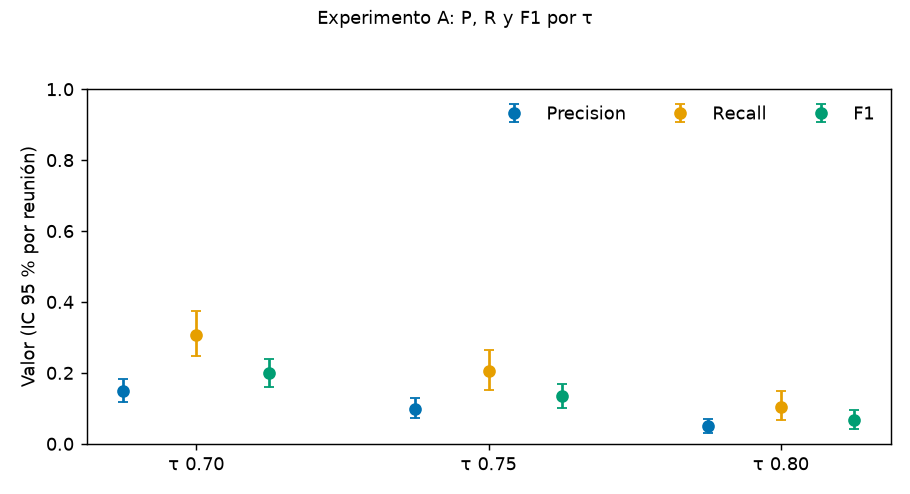

b-correct


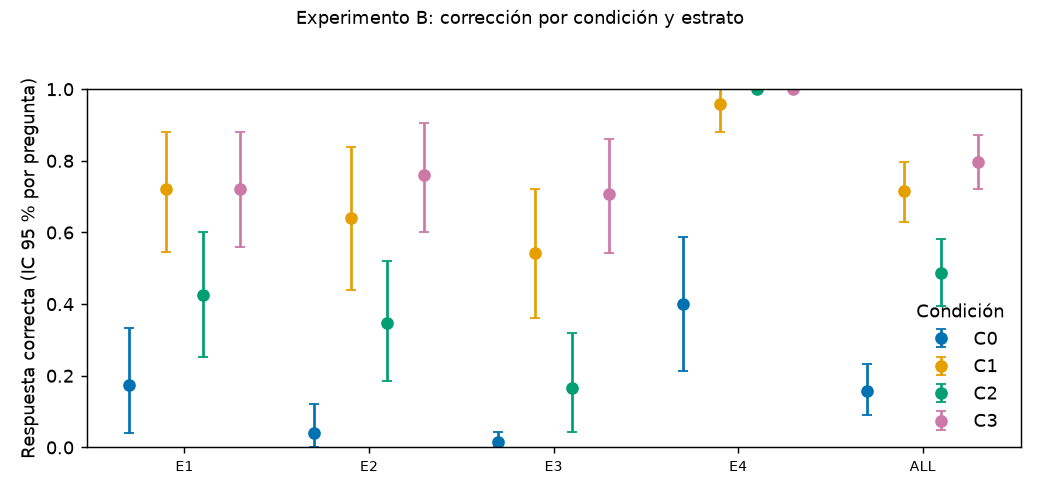

cost-latency


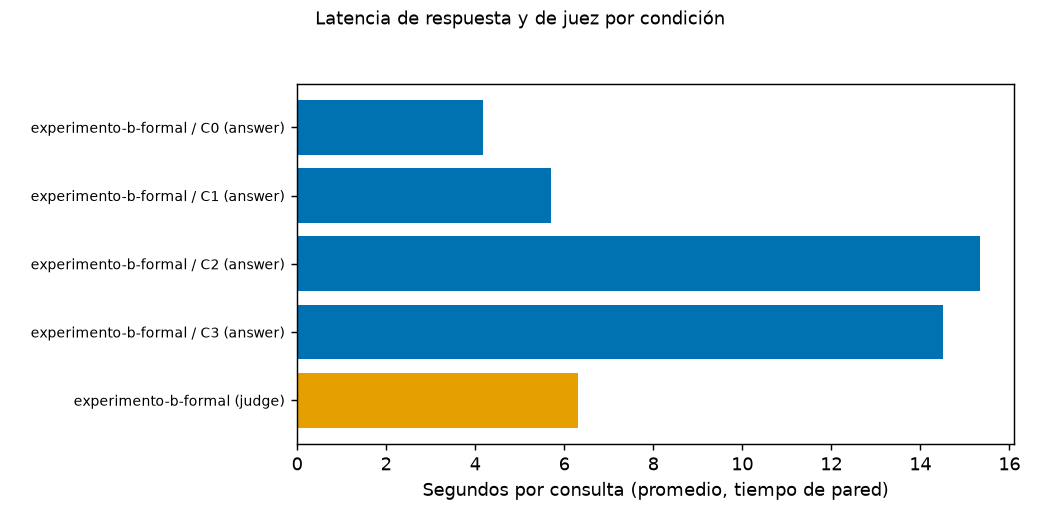

oe4-stages


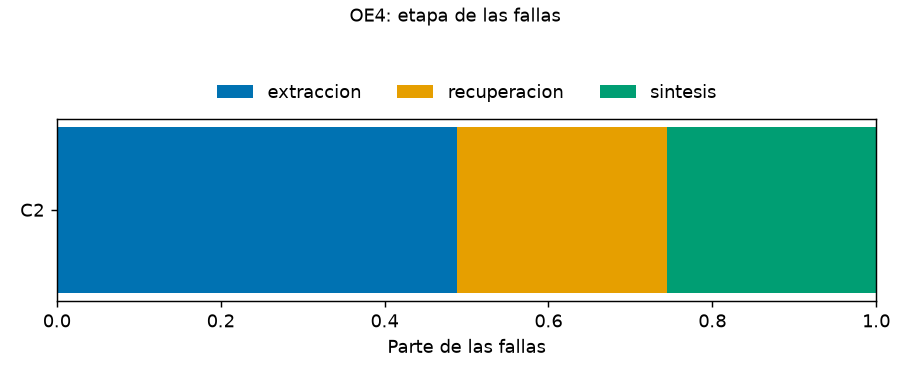

In [11]:
names = ("a-headline", "b-correct", "cost-latency", "oe4-stages")
expected = [FIGURES_DIR / f"{SET}-{n}.png" for n in names]
if all(p.is_file() for p in expected):
    figure_paths, origin = expected, "reports/figures/"
else:
    tmp = Path(tempfile.mkdtemp(prefix="figuras-finales-"))
    figure_paths = draw_all(FinalTables(tables=TABLES, stamped=False), SET, tmp)
    origin = "regeneradas desde las tablas (carpeta temporal)"
print("Figuras:", origin)
assert len(figure_paths) == 4
for path in figure_paths:
    print(path.stem.removeprefix(f"{SET}-"))
    display(Image(filename=str(path)))

---

# 6. Validez del juez automático

**Pregunta.** ¿En qué medida se pueden fiar las cifras de OE3 del juez automático?

**Qué se muestra.** El acuerdo del juez con la verificación humana (240 respuestas, 60 por condición),
tal como lo guarda `juez-humano.json`. Los kappas por condición se recalculan desde las dos hojas, igual que en el notebook 30, sección 3.

In [12]:
rows = []
for column in juez["columns"] + [juez["outdated"]]:
    kappa = column["kappa"]
    rows.append(
        {
            "etiqueta": column["column"],
            "ítems": column["n_items"],
            "acuerdo observado": es(column["observed_agreement"], 3),
            "kappa": "indefinido" if kappa is None else es(kappa, 3),
            f"cumple {es(juez['min_kappa'])}": "sí" if column["passes"] else "no",
        }
    )
display(pd.DataFrame(rows).set_index("etiqueta"))
correct_kappa = next(c for c in juez["columns"] if c["column"] == "correct")["kappa"]
evidence_kappa = next(c for c in juez["columns"] if c["column"] == "evidence_supported")["kappa"]
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    by_condition = check_judge_by_condition(
        read_csv_rows(B_DIR / "muestra-juez.clave.csv"),
        read_csv_rows(B_DIR / "muestra-juez.csv"),
        min_kappa=juez["min_kappa"],
    )
BY_CONDITION = {c: check.columns[0].kappa for c, check in by_condition.items()}
display(
    pd.DataFrame(
        {
            "kappa de `correct`": {c: es(k, 3) for c, k in BY_CONDITION.items()},
            f"cumple {es(juez['min_kappa'])}": {
                c: "sí" if check.columns[0].passes else "no" for c, check in by_condition.items()
            },
        }
    ).rename_axis("condición (60 ítems cada una; exploratorio)")
)
display(
    Markdown(
        f"**Lectura.** `correct` cumple (kappa {es(correct_kappa, 3)}) "
        "y las comparaciones entre C1, C2 y C3 "
        "descansan en un juez confiable para esa etiqueta. En "
        "C0 el kappa queda por debajo del umbral "
        f"({es(BY_CONDITION['C0'], 3)}) porque el juez es más "
        "estricto que las personas: la corrección de C0 "
        "probablemente está subestimada y las diferencias frente "
        "a C0 podrían estar sobreestimadas. "
        f"`evidence_supported` no es confiable (kappa {es(evidence_kappa, 3)}) "
        "y solo debe leerse como "
        f"descriptiva. `outdated` no tuvo ninguna marca positiva: **H4 no es evaluable**."
    )
)

,ítems,acuerdo observado,kappa,"cumple 0,70"
etiqueta,,,,
correct,240,"0,904","0,807",sí
evidence_supported,240,"0,754","0,438",no
outdated,42,"1,000",indefinido,no


,kappa de `correct`,"cumple 0,70"
condición (60 ítems cada una; exploratorio),,
C0,"0,484",no
C1,"0,718",sí
C2,"0,899",sí
C3,"0,896",sí


**Lectura.** `correct` cumple (kappa 0,807) y las comparaciones entre C1, C2 y C3 descansan en un juez confiable para esa etiqueta. En C0 el kappa queda por debajo del umbral (0,484) porque el juez es más estricto que las personas: la corrección de C0 probablemente está subestimada y las diferencias frente a C0 podrían estar sobreestimadas. `evidence_supported` no es confiable (kappa 0,438) y solo debe leerse como descriptiva. `outdated` no tuvo ninguna marca positiva: **H4 no es evaluable**.

---

# 7. Lectura de conjunto y limitaciones

**Lectura.**

In [13]:
d_e3 = -paired("C2", "C3", "E3")["difference"]
display(
    Markdown(
        "- **La arquitectura compilada es viable cuando las decisiones "
        "son buenas.** C2 y C3 comparten el "
        "código de consulta y difieren solo en las decisiones; "
        "con las de la referencia, la corrección en E3 "
        f"pasa de {es(point('C2', 'E3'))} (C2) a {es(point('C3', 'E3'))} "
        f"(C3), una brecha de {es(d_e3)}. "
        f"Con ellas, C3 queda en {es(point('C3', 'ALL'))} en el "
        f"total frente a {es(point('C1', 'ALL'))} de C1 "
        f"(lectura descriptiva).\n"
        f"- **El cuello de botella es la extracción automática con un modelo local pequeño.** Con "
        f"`{manifest_b['settings']['generative_model']}` la extracción "
        f"encuentra {es(pooled['recall'], 3)} de las "
        "decisiones de la referencia (OE2) y la etapa más frecuente "
        "del fallo de C2 es la extracción "
        f"({pct(todas.loc['extraccion', 'share'])} de {int(todas['n_failures'].iloc[0])} "
        "respuestas incorrectas, OE4).\n"
        f"- **Costo.** Una consulta de C2 es {es(ratio, 1)} veces "
        "más lenta que una de C1 y no hay punto de equilibrio.\n"
        "- **Hipótesis.** D16 y H1 no se respaldan para C2; H2 "
        "y H3 son no concluyentes; H4 no es evaluable."
    )
)

- **La arquitectura compilada es viable cuando las decisiones son buenas.** C2 y C3 comparten el código de consulta y difieren solo en las decisiones; con las de la referencia, la corrección en E3 pasa de 0,17 (C2) a 0,71 (C3), una brecha de 0,54. Con ellas, C3 queda en 0,80 en el total frente a 0,72 de C1 (lectura descriptiva).
- **El cuello de botella es la extracción automática con un modelo local pequeño.** Con `qwen3:8b` la extracción encuentra 0,308 de las decisiones de la referencia (OE2) y la etapa más frecuente del fallo de C2 es la extracción (48,8 % de 43 respuestas incorrectas, OE4).
- **Costo.** Una consulta de C2 es 2,7 veces más lenta que una de C1 y no hay punto de equilibrio.
- **Hipótesis.** D16 y H1 no se respaldan para C2; H2 y H3 son no concluyentes; H4 no es evaluable.

**Limitaciones.**

- **C3 es una referencia solo para las decisiones.** Sus conceptos, eventos, proyectos y fuentes siguen
  siendo los de la extracción automática; no es un techo teórico de lo que OpenKOS podría lograr.
- **C3 frente a C1 no fue una hipótesis preregistrada.** Comparar sus tasas es una lectura descriptiva y no
  sostiene ninguna afirmación de significancia.
- **Dos causas confundidas en la extracción.** El diseño de extracción de OpenKOS y la capacidad del
  modelo local (`qwen3:8b`) no se separan en este diseño: no se puede atribuir el fallo a una sola.
  El modelo grande (`generative_model_large`) está configurado pero no se corrió.
- **Juez.** `evidence_supported` no es confiable, H4 no es evaluable y el kappa de C0 queda bajo el umbral.
  Hay dos posibles falsos negativos señalados en el notebook 30 (q015 y q019) que no cambian ninguna cifra.
- **Una sola corrida formal por experimento**, un generador local pequeño, 25 preguntas por estrato (24 en
  E3) y 3 repeticiones promediadas por pregunta; los intervalos son anchos y las cifras por estrato son
  descriptivas.
- **Referencia.** En siete de las once series de evaluación la referencia viene de un solo anotador; la
  confiabilidad se midió solo en las cuatro series de control.
- **Costo.** Son tiempos de pared de una máquina concreta; los tokens no se registran y no se midió memoria.
- **La implicación práctica es una hipótesis, no un resultado.** Capturar decisiones con una persona en el
  circuito y usar RAG como respaldo es una línea de trabajo futuro que estos datos sugieren (C3 mejora a C2),
  pero que este proyecto no probó.